# Empirical covariates: what does masking actually change?

Build a small OBS–RCT task from **32 invented rows**, inspect its exact target, and then optionally use separately obtained IHDP or ACIC2016 files. No external data or downloads are needed for the default run.

You will see why a hidden column need not create residual confounding under a finite empirical distribution, how explicit coarsening changes the estimand, and why the target CATE differs from a row's full-information effect. This notebook illustrates a data contract and its consequences; it does not compare estimator performance.

Install the repository's `notebooks` extra before launching Jupyter. Once the package is installed, these cells work from any working directory. The default examples are deliberately small; larger experiments belong on a compute server.


In [1]:
%matplotlib inline
import os

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from obs_rct_benchmark.datasets import (
    EmpiricalDGPConfig,
    EmpiricalPopulation,
    generate_empirical_problem,
    load_acic2016,
    load_ihdp_csv,
    load_ihdp_npz,
)

plt.rcParams.update({"figure.figsize": (9, 3.5), "axes.spines.top": False,
                     "axes.spines.right": False})


## Declare the population before sampling

Give every invented row probability $1/N$. A row contains a visible candidate $V$, a variable $U$ that we will hide, and potential-outcome means $\mu_0$ and $\mu_1$. The row effect is $\mu_1-\mu_0$.

The learner's target is instead

$$\tau(x)=\mathbb{E}[\mu_1(\mathrm{row})-\mu_0(\mathrm{row})\mid X_{\mathrm{displayed}}=x].$$

That expectation averages over all population rows with the same **displayed** covariates. It depends on the declared representation, including any coarsening. Full rows and potential means remain evaluator-owned; they are shown here only because this entire population is invented.


In [2]:
# Edit these controls and rerun from this cell. Keep N_ROWS divisible by 2 * BINS
# so each bin has equal numbers of the two hidden values used by our hand check.
SEED = 17
N_ROWS = 32
BINS = 4
GAMMA = 3.0
NOISE_STD = 0.2
assert BINS >= 1 and N_ROWS >= 2 * BINS and N_ROWS % (2 * BINS) == 0
assert GAMMA >= 1

v = np.linspace(-1.0, 1.0, N_ROWS)
u = np.tile([-1.0, 1.0], N_ROWS // 2)
mu0 = 1.0 + 0.5 * v + 0.8 * u
mu1 = mu0 + 1.0 + v + 0.6 * u
population = EmpiricalPopulation(
    X_full=np.column_stack([v, u]),
    feature_names=("visible", "hidden"),
    mu0=mu0,
    mu1=mu1,
    provenance={"source_id": "invented_notebook"},
)
row_effect = mu1 - mu0
budgets = dict(n_obs=120, n_rct_train=60, n_rct_tune=30,
               n_rct_test=30, n_eval=128)


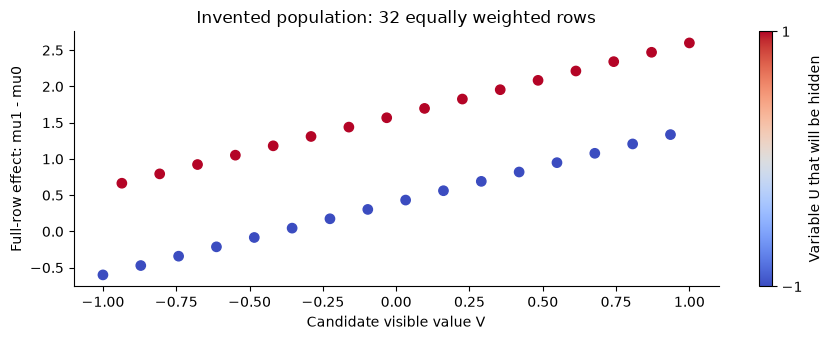

In [3]:
fig, ax = plt.subplots()
scatter = ax.scatter(v, row_effect, c=u, cmap="coolwarm", s=45)
ax.set(xlabel="Candidate visible value V", ylabel="Full-row effect: mu1 - mu0",
       title="Invented population: 32 equally weighted rows")
fig.colorbar(scatter, ax=ax, label="Variable U that will be hidden", ticks=[-1, 1])
plt.tight_layout()
plt.show()


## Masking a column can leave no conditional ambiguity

Every value of $V$ above is unique. In this **finite empirical law**, conditioning on its exact value identifies the row and therefore also its hidden $U$. Dropping the $U$ column does not leave hidden variation conditional on displayed $X=V$.

The generator rejects this case by default. An explicit negative control can permit it; its realized sensitivity parameter is 1 even if we request a larger bound. This statement concerns the declared finite population, not an assertion that a continuous variable removes unmeasured confounding in a new superpopulation.


In [4]:
unique_config = EmpiricalDGPConfig(
    name="invented_unique_visible", hidden_columns=("hidden",), gamma=GAMMA,
    noise_std=NOISE_STD, **budgets,
)
try:
    generate_empirical_problem(population, unique_config, SEED)
except ValueError as error:
    assert "no within-visible-group variation" in str(error)
    print("Expected rejection: exact visible values identify every invented row.")
else:
    raise AssertionError("This population should require an explicit negative control.")

negative_config = EmpiricalDGPConfig(
    name="invented_unique_negative_control", hidden_columns=("hidden",),
    allow_no_hidden_ambiguity=True, gamma=GAMMA, noise_std=NOISE_STD, **budgets,
)
negative = generate_empirical_problem(population, negative_config, SEED)
assert not negative.metadata["diagnostics"]["has_hidden_ambiguity"]
np.testing.assert_allclose(negative.truth.eval["gamma_required"], 1.0)
np.testing.assert_allclose(negative.truth.eval["confounding_cate_bias"], 0.0, atol=1e-12)
print("Explicit negative control: no hidden ambiguity, realized Gamma = 1.")


Expected rejection: exact visible values identify every invented row.
Explicit negative control: no hidden ambiguity, realized Gamma = 1.


## Coarsen explicitly, and report the new target

Now display only the empirical quantile-bin label of $V$, while still hiding $U$. Each bin contains several rows and both hidden values. This creates residual hidden variation under the finite law.

This operation changes the target from $\tau(V)$ to $\tau(\mathrm{bin}(V))$. The bin boundaries are defined from the fixed covariate population before role sampling and use no outcomes. Hiding an ACIC categorical source column similarly removes all of its one-hot indicators together. Coarsening is a scientific design choice, not an invisible preprocessing step.


In [5]:
config = EmpiricalDGPConfig(
    name="invented_visible_bins", hidden_columns=("hidden",),
    visible_binning=(("visible", BINS),), gamma=GAMMA,
    noise_std=NOISE_STD, **budgets,
)
problem = generate_empirical_problem(population, config, SEED)
diagnostics = problem.metadata["diagnostics"]
summary_rows = [
    ("Population rows", diagnostics["population_rows"]),
    ("Distinct displayed-X groups", diagnostics["visible_groups"]),
    ("Rows with hidden ambiguity", f'{diagnostics["hidden_ambiguity_row_fraction"]:.0%}'),
    ("Requested Gamma", f'{GAMMA:g}'),
    ("Maximum realized Gamma", f'{diagnostics["gamma_realized_max"]:.3f}'),
]
display(Markdown("| Quantity | Value |\n| --- | ---: |\n" +
                 "\n".join(f"| {name} | {value} |" for name, value in summary_rows)))


| Quantity | Value |
| --- | ---: |
| Population rows | 32 |
| Distinct displayed-X groups | 4 |
| Rows with hidden ambiguity | 100% |
| Requested Gamma | 3 |
| Maximum realized Gamma | 3.000 |

## Verify the oracle by enumerating the population

Do not infer correctness from a clean plot. The following check groups invented rows in ordinary Python dictionaries and computes conditional means directly, without calling the generator's truth helpers.

For this balanced two-value hidden variable, $e=P(T=1\mid X)=1/2$ and

$$p(U=-1)=\frac{1}{1+\Gamma},\qquad p(U=+1)=\frac{\Gamma}{1+\Gamma}.$$

Their mean is $1/2$, and their odds relative to the marginal odds obey the $\Gamma$ bound. Bayes weights give $E[\mu_1\mid X,T=1]$ and $E[\mu_0\mid X,T=0]$. Their difference is the naive observational regression contrast; it need not equal the target CATE.


In [6]:
# Apply the documented quantile rule, then enumerate exact displayed-X groups.
edges = np.unique(np.quantile(v, np.arange(1, BINS) / BINS))
bin_id = np.searchsorted(edges, v, side="right")
groups = {}
for row, label in enumerate(bin_id):
    groups.setdefault(int(label), []).append(row)

hand = {}
p_full = np.where(u < 0, 1.0 / (1.0 + GAMMA), GAMMA / (1.0 + GAMMA))
for label, rows in groups.items():
    assert sum(u[j] for j in rows) == 0  # balanced support in this example
    target0 = sum(mu0[j] for j in rows) / len(rows)
    target1 = sum(mu1[j] for j in rows) / len(rows)
    selected0 = sum(mu0[j] * (1 - p_full[j]) for j in rows) / sum(1 - p_full[j] for j in rows)
    selected1 = sum(mu1[j] * p_full[j] for j in rows) / sum(p_full[j] for j in rows)
    hand[label] = dict(tau=target1 - target0, selected0=selected0, selected1=selected1)

labels_at_eval = problem.eval_X[:, 0].astype(int)
np.testing.assert_allclose(problem.eval_tau, [hand[k]["tau"] for k in labels_at_eval])
np.testing.assert_allclose(problem.truth.eval["mu0_obs_regression"],
                           [hand[k]["selected0"] for k in labels_at_eval])
np.testing.assert_allclose(problem.truth.eval["mu1_obs_regression"],
                           [hand[k]["selected1"] for k in labels_at_eval])
print("Exact enumeration agrees with target CATE and both selected-arm means.")


Exact enumeration agrees with target CATE and both selected-arm means.


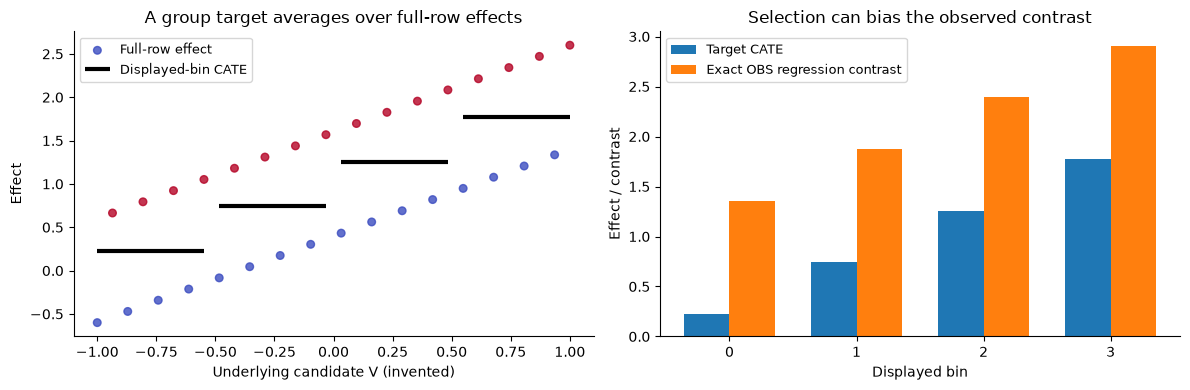

In [7]:
keys = sorted(groups)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(v, row_effect, c=u, cmap="coolwarm", s=30, alpha=0.8,
                label="Full-row effect")
for index, label in enumerate(keys):
    rows = groups[label]
    axes[0].hlines(hand[label]["tau"], v[rows].min(), v[rows].max(),
                   colors="black", linewidth=3,
                   label="Displayed-bin CATE" if index == 0 else None)
axes[0].set(xlabel="Underlying candidate V (invented)", ylabel="Effect",
            title="A group target averages over full-row effects")
axes[0].legend(fontsize=9)

positions = np.arange(len(keys))
target = np.array([hand[k]["tau"] for k in keys])
obs_contrast = np.array([hand[k]["selected1"] - hand[k]["selected0"] for k in keys])
axes[1].bar(positions - 0.18, target, width=0.36, label="Target CATE")
axes[1].bar(positions + 0.18, obs_contrast, width=0.36,
            label="Exact OBS regression contrast")
axes[1].set(xticks=positions, xticklabels=keys, xlabel="Displayed bin",
            ylabel="Effect / contrast", title="Selection can bias the observed contrast")
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()


## Generate fresh treatment and outcome, then separate roles

OBS selects treatment using the hidden-dependent probabilities above. RCT treatment is randomized at its configured probability. For each sampled row, a **new** outcome is generated from the selected arm mean plus new noise.

All roles draw independently with replacement from the declared population. A population row can therefore appear in several roles. This evaluates generalization under that fixed empirical law; it does not establish performance on unseen people from an unknown population. In the file adapters, historical treatment, factual outcomes and noisy counterfactual outcomes are validated and discarded.

An estimator receives only `TrainingView`. Population rows, potential means, exact OBS propensities, target effects, and evaluator-owned RCT test data are not fields in that view. The truth above is explicitly an oracle diagnostic, never a fitted estimator.


In [8]:
training = problem.training_view()
assert not hasattr(training, "truth") and not hasattr(training, "population")
assert not hasattr(training, "rct_test")
assert training.obs_train.known_propensity is None
assert not training.obs_train.X.flags.writeable
role_rows = [
    (name, getattr(training, name).n, getattr(training, name).d)
    for name in ("obs_train", "rct_train", "rct_tune")
]
display(Markdown("| Estimator role | Rows | Displayed features |\n| --- | ---: | ---: |\n" +
                 "\n".join(f"| {name} | {n} | {d} |" for name, n, d in role_rows)))


| Estimator role | Rows | Displayed features |
| --- | ---: | ---: |
| obs_train | 120 | 1 |
| rct_train | 60 | 1 |
| rct_tune | 30 | 1 |

## A selection bound is not a fixed amount of outcome bias

$\Gamma$ bounds the odds of hidden-dependent treatment selection relative to the marginal propensity. Its effect on the observed outcome contrast also depends on the outcome means. Here both $\mu_0$ and $\mu_1$ depend on hidden $U$; the observational contrast is biased even though the marginal treatment probability is exactly $1/2$ in every bin.

Use $\Gamma=1$ as a negative control. It removes hidden treatment selection in this construction without changing the displayed-bin target. Try changing the hidden outcome coefficients in the population cell, keeping $\Gamma$ fixed, and compare the exact bias. Avoid treating one construction or one outcome specification as the entire sensitivity model.


In [9]:
no_selection_config = EmpiricalDGPConfig(
    name="invented_gamma_one", hidden_columns=("hidden",),
    visible_binning=(("visible", BINS),), gamma=1.0,
    noise_std=NOISE_STD, **budgets,
)
no_selection = generate_empirical_problem(population, no_selection_config, SEED)
np.testing.assert_allclose(no_selection.truth.eval["confounding_cate_bias"], 0, atol=1e-12)
assert no_selection.metadata["visible_transform_sha256"] == problem.metadata["visible_transform_sha256"]
print("Gamma = 1: exact confounding bias is zero; the declared visible target is unchanged.")


Gamma = 1: exact confounding bias is zero; the declared visible target is unchanged.


## Optional: use your own IHDP or ACIC2016 files

The next two cells are disabled by default. Obtain files separately under their applicable terms, keep them outside this repository, and supply paths through environment variables. This notebook performs no download and displays no real-data rows or local paths. Read [dataset sources, terms and schemas](https://github.com/snu-causality-lab/obs-rct-benchmark/blob/main/docs/DATASETS.md) before use.

Both potential-outcome **means** (`mu0`, `mu1`) are required for the `loaded_means` outcome model used here. Noisy potential outcomes alone are not interchangeable with means. A covariate-only population can instead use the explicitly declared `outcome_model="synthetic"` API, which defines a different outcome DGP.

Choose source column names to retain and declare every numeric quantile transform. The one-column/two-bin setting below is an illustration, not a canonical IHDP/ACIC protocol. ACIC text covariates are encoded by the loader; supply `categorical_columns` for numeric-coded categories, `column_map` for noncanonical response headers, and `row_id_columns` where available. Without IDs, equal row counts alone cannot establish correct row linkage. Real-data adapters generate **new** OBS/RCT tasks; their results are not original IHDP/ACIC benchmark scores.


In [10]:
RUN_EXTERNAL = False  # Set True only after supplying permitted local input files.
EXTERNAL_DATASET = "ihdp-npz"  # "ihdp-npz", "ihdp-csv", or "acic2016"
REPLICATION = 0
EXTERNAL_KEEP_COLUMNS = ("x1",)  # Edit to match your source schema.
EXTERNAL_VISIBLE_BINNING = (("x1", 2),)
ACIC_COLUMN_MAP = None
ACIC_CATEGORICAL_COLUMNS = ()
ACIC_ROW_ID_COLUMNS = None

# Set outside the notebook kernel, or through your own secure local setup:
# IHDP NPZ/CSV: OBSRCT_IHDP_TRAIN; optional NPZ split: OBSRCT_IHDP_TEST
# ACIC CSVs:   OBSRCT_ACIC_X and OBSRCT_ACIC_RESPONSE
# Do not place local paths or real input files in a committed notebook.


In [11]:
if not RUN_EXTERNAL:
    print("External data skipped. All preceding results use invented rows only.")
else:
    # Suppress input-dependent exception text so local paths/values do not enter outputs.
    try:
        if EXTERNAL_DATASET == "ihdp-npz":
            external_population = load_ihdp_npz(
                os.environ["OBSRCT_IHDP_TRAIN"], os.environ.get("OBSRCT_IHDP_TEST"),
                replication=REPLICATION,
            )
        elif EXTERNAL_DATASET == "ihdp-csv":
            if REPLICATION != 0:
                raise ValueError("CSV has no replication axis")
            external_population = load_ihdp_csv(os.environ["OBSRCT_IHDP_TRAIN"])
        elif EXTERNAL_DATASET == "acic2016":
            external_population = load_acic2016(
                os.environ["OBSRCT_ACIC_X"], os.environ["OBSRCT_ACIC_RESPONSE"],
                column_map=ACIC_COLUMN_MAP,
                categorical_columns=ACIC_CATEGORICAL_COLUMNS,
                row_id_columns=ACIC_ROW_ID_COLUMNS,
            )
        else:
            raise ValueError("Unknown external dataset")
        source_columns = tuple(dict.fromkeys(external_population.feature_groups))
        if not EXTERNAL_KEEP_COLUMNS or not set(EXTERNAL_KEEP_COLUMNS) <= set(source_columns):
            raise ValueError("Retained columns do not match source schema")
        external_config = EmpiricalDGPConfig(
            name="local_empirical_notebook",
            dataset_id="acic2016" if EXTERNAL_DATASET == "acic2016" else "ihdp",
            replication=REPLICATION,
            hidden_columns=tuple(c for c in source_columns if c not in EXTERNAL_KEEP_COLUMNS),
            visible_binning=EXTERNAL_VISIBLE_BINNING, outcome_model="loaded_means",
            gamma=GAMMA, noise_std=NOISE_STD, **budgets,
        )
        external_problem = generate_empirical_problem(external_population, external_config, SEED)
    except (OSError, ValueError, KeyError, RuntimeError):
        raise RuntimeError(
            "External-data step failed. Check local environment variables, loader schema, "
            "potential means, retained columns, row alignment and conditional hidden ambiguity. "
            "Input-dependent error text is omitted."
        ) from None
    external_diagnostics = external_problem.metadata["diagnostics"]
    safe_summary = [
        ("Population rows", external_diagnostics["population_rows"]),
        ("Displayed-X groups", external_diagnostics["visible_groups"]),
        ("Rows with hidden ambiguity", f'{external_diagnostics["hidden_ambiguity_row_fraction"]:.1%}'),
        ("Maximum realized Gamma", f'{external_diagnostics["gamma_realized_max"]:.3f}'),
    ]
    display(Markdown("| Aggregate diagnostic | Value |\n| --- | ---: |\n" +
                     "\n".join(f"| {name} | {value} |" for name, value in safe_summary)))


External data skipped. All preceding results use invented rows only.


## What to record when turning this into an experiment

Record the data release and applicable terms, selected replication, input hashes, fixed-population definition, encoded source columns, hidden columns, coarsening, potential-mean specification, role budgets, treatment mechanism and independent seeds. The generator metadata provides structural diagnostics and hashes without input paths or raw rows. Keep real-data notebook outputs private unless the relevant terms permit sharing them.

For a method comparison, use the same realized problem for every method, pass only `problem.training_view()` to fitting, and compare predictions at `problem.eval_X` against `problem.eval_tau` with the benchmark runner. Use enough independent replicates for the intended scientific claim; this notebook's small samples only demonstrate mechanics. Freeze evaluation designs separately from settings used to develop a method.

Useful follow-ups:

- Change `BINS` while keeping the full row population fixed. Both hidden ambiguity and the target change; avoid interpreting resulting score changes as difficulty alone.
- Set `GAMMA=1` for a zero-selection-bias control. Removing explicit U terms alone need not remove bias: after binning, the unobserved within-bin V still affects outcomes and can be associated with U. A separate zero-outcome-confounding control must make each arm mean depend only on the displayed bin, with no within-bin outcome variation.
- Compare covariate-only synthetic outcomes with loaded potential means, reporting them as different DGPs.

See [the evaluation protocol](https://github.com/snu-causality-lab/obs-rct-benchmark/blob/main/docs/PROTOCOL.md), [the sensitivity construction](https://github.com/snu-causality-lab/obs-rct-benchmark/blob/main/docs/SENSITIVITY.md), and [dataset references and licensing details](https://github.com/snu-causality-lab/obs-rct-benchmark/blob/main/docs/DATASETS.md). Hill (2011) and Dorie et al. (2019) describe the source semi-synthetic benchmarks; the adapted task in this notebook uses a separately declared estimand and sampling mechanism.
